# Air Quality Prediction (PM2.5 Forecasting)

End-to-end exploratory data analysis, leak-free next-day (`t+1`) **PM2.5** forecasting using `LinearRegression`, and an interactive 50-city monitoring dashboard.

### Dataset
- **File:** `dataset/air_quality_daily.csv` (`78,500` rows × `19` columns, `2022-08-05` → `2026-11-21`, `50` cities, zero missing values)
- **Source:** [AkshayKarthick/india-weather-air-quality](https://huggingface.co/datasets/AkshayKarthick/india-weather-air-quality) (`air_quality_daily.csv`)

### Pipeline Overview
1. **Data Loading & Preparation** - Load `dataset/air_quality_daily.csv`, parse `date`, encode `city_id`, and extract calendar features.
2. **Exploratory Data Analysis & PACF** - Examine pollutant correlations with `pm2_5_mean`, AQI category breakdown, city rankings, and single-city partial autocorrelation (`visualizations/eda_overview.png`, `visualizations/delhi_pacf.png`).
3. **Feature Engineering & Model Training** - Build city-grouped lag/rolling features, split chronologically per city (`80/10/10`), train `LinearRegression` for next-day `pm2_5_mean`, evaluate diagnostics (`visualizations/model_evaluation.png`), and save `model/air_quality_linear_regression_model.pkl`.
4. **Interactive City Dashboard** - Inspect next-day forecasts, 30-day actual vs. predicted trends (`visualizations/city_dashboard_overview.png`), and a 50-city Folium map exported to `visualizations/air_quality_map.html`.

## 1. Environment Setup & Data Loading

In [1]:
# pip install numpy pandas matplotlib seaborn scikit-learn statsmodels folium ipywidgets joblib

import os
from math import sqrt
from typing import TypedDict

import folium
import ipywidgets as widgets
import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, IFrame, clear_output, display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.stattools import pacf

os.makedirs('dataset', exist_ok=True)
os.makedirs('model', exist_ok=True)
os.makedirs('visualizations', exist_ok=True)

sns.set_theme(style='whitegrid')

df = pd.read_csv('dataset/air_quality_daily.csv')
df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d')

CITY_MAP = {c: i for i, c in enumerate(sorted(df['city'].unique()))}
df['city_id'] = df['city'].map(CITY_MAP)
df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.day_of_week
df['day_of_year'] = df['date'].dt.day_of_year
df = df.sort_values(['city_id', 'date']).reset_index(drop=True)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date range: {df['date'].min().date()} -> {df['date'].max().date()} | Cities: {df['city'].nunique()}")
print(f"Total missing values: {int(df.isna().sum().sum())}")
df.head(3)

Dataset shape: 78,500 rows x 23 columns
Date range: 2022-08-05 -> 2026-11-21 | Cities: 50
Total missing values: 0


,date,city,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,...,hours_available,india_aqi,india_aqi_category,dominant_pollutant,india_aqi_pm,india_aqi_pm_category,city_id,month,day_of_week,day_of_year
0,2022-08-05,Agartala,14.09,19.1,20.50,27.6,20.63,2.32,72.0,204.75,...,24,72,Satisfactory,O3,23,Good,0,8,4,217
1,2022-08-06,Agartala,12.12,19.3,17.44,27.7,23.11,1.10,48.0,208.00,...,24,48,Good,O3,20,Good,0,8,5,218
2,2022-08-07,Agartala,11.85,19.0,17.18,27.6,22.27,1.18,75.0,238.38,...,24,75,Satisfactory,O3,20,Good,0,8,6,219


## 2. Exploratory Data Analysis (EDA) & Lag Selection

Examine feature correlations with `pm2_5_mean`, AQI category distribution, highest-PM2.5 cities, and single-city PACF (`Delhi`) to verify lag depth.

Correlation with pm2_5_mean:


pm2_5_mean    1.0000
pm2_5_max     0.9671
co_8h_max     0.7015
pm10_mean     0.6929
no2_mean      0.5979
pm10_max      0.5956
aod_mean      0.5351
o3_8h_max     0.5346
so2_mean      0.4406
dust_mean     0.2020
Name: pm2_5_mean, dtype: float64

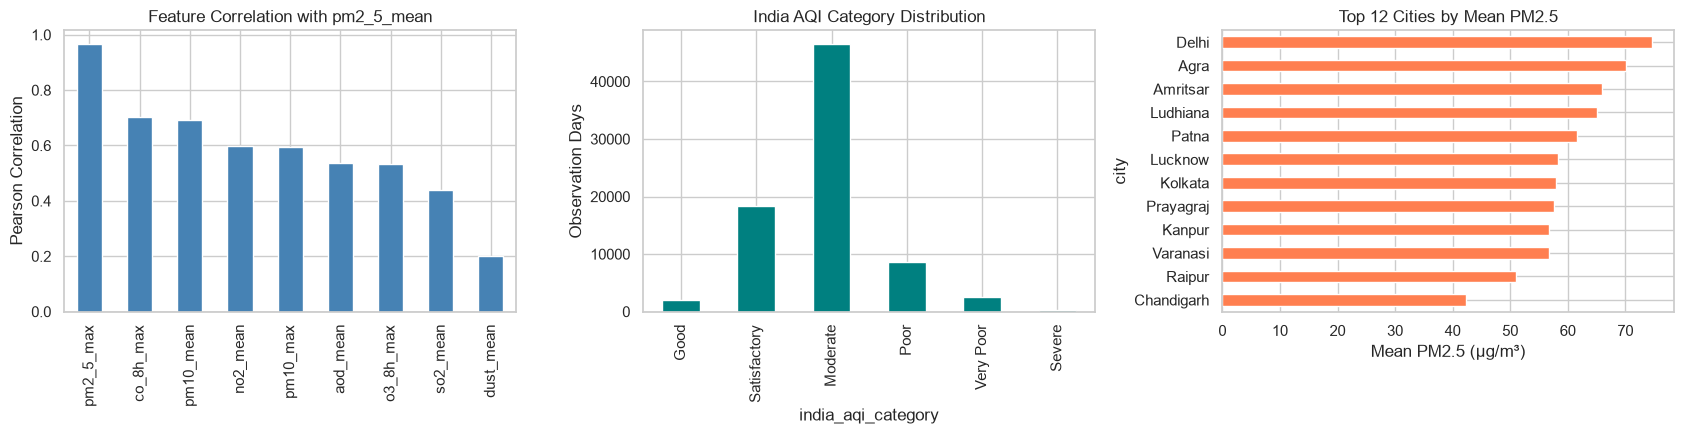

In [2]:
pollutant_cols = [
    'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max',
    'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max',
    'dust_mean', 'aod_mean'
]

corr = df[pollutant_cols].corr()['pm2_5_mean'].sort_values(ascending=False)
print("Correlation with pm2_5_mean:")
display(corr.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

corr.drop('pm2_5_mean').plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Feature Correlation with pm2_5_mean')
axes[0].set_ylabel('Pearson Correlation')
axes[0].axhline(0, color='black', linewidth=0.8)

cat_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
cat_counts = df['india_aqi_category'].value_counts().reindex(cat_order, fill_value=0)
cat_counts.plot(kind='bar', ax=axes[1], color='teal')
axes[1].set_title('India AQI Category Distribution')
axes[1].set_ylabel('Observation Days')

top_cities = df.groupby('city')['pm2_5_mean'].mean().sort_values(ascending=False).head(12)
top_cities.sort_values().plot(kind='barh', ax=axes[2], color='coral')
axes[2].set_title('Top 12 Cities by Mean PM2.5')
axes[2].set_xlabel('Mean PM2.5 (µg/m³)')

plt.tight_layout()
fig.savefig('visualizations/eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

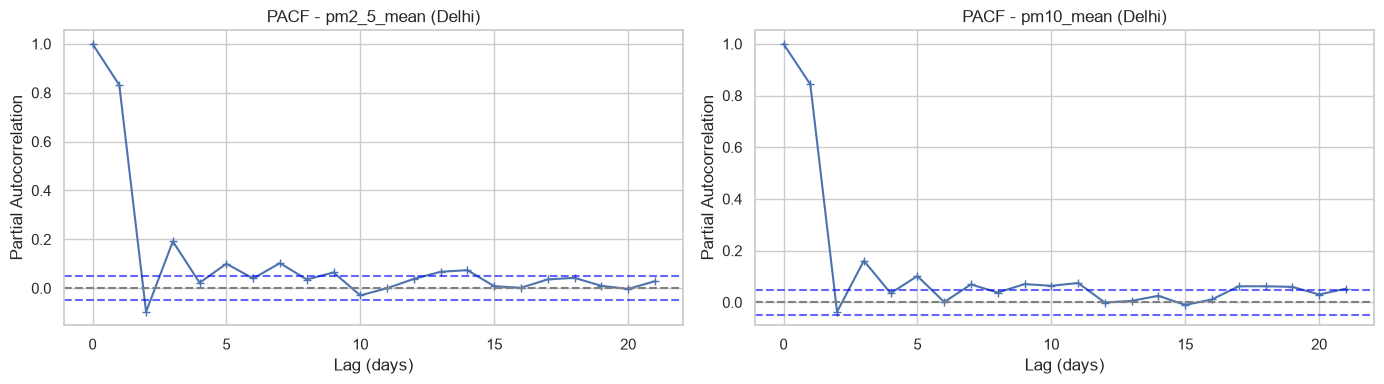

In [3]:
# Single-city PACF (Delhi) to avoid cross-city boundary artifacts
delhi_df = df[df['city'] == 'Delhi'].sort_values('date')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['pm2_5_mean', 'pm10_mean']):
    series = delhi_df[col].to_numpy(dtype=float)
    lag_pacf = pacf(series, nlags=21, method='ols')
    conf = 1.96 / np.sqrt(len(series))
    ax.plot(lag_pacf, marker='+')
    ax.axhline(0, linestyle='dashed', color='gray')
    ax.axhline(-conf, linestyle='dashed', color='blue', alpha=0.6)
    ax.axhline(conf, linestyle='dashed', color='blue', alpha=0.6)
    ax.set_title(f'PACF - {col} (Delhi)')
    ax.set_xlabel('Lag (days)')
    ax.set_ylabel('Partial Autocorrelation')

plt.tight_layout()
fig.savefig('visualizations/delhi_pacf.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. City-Grouped Feature Engineering & Next-Day (`t+1`) Modeling

### Pipeline Guarantees
- **No cross-city leakage:** All `shift()` and `rolling()` operations run strictly inside `groupby('city_id')`.
- **Contiguous daily transitions:** Verifies exact 1-day spacing across lags (`1, 2, 3` days) and target (`t+1`).
- **True next-day forecasting:** Uses day-`t` pollutant/AOD/calendar measurements and past lags/rolling means to predict `pm2_5_mean` at day `t+1` (`target_pm25`), excluding target-derived AQI summary labels (`india_aqi`, `us_aqi_max`, `india_aqi_pm`, etc.).
- **Chronological per-city split:** `80%` Train / `10%` Validation / `10%` Test ordered by `date` within each of the 50 cities.

In [4]:
BASE_FEATURE_COLS = [
    'city_id', 'month', 'day_of_week', 'day_of_year',
    'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max',
    'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max',
    'dust_mean', 'aod_mean',
]
ROLLING_COLS = [
    'pm2_5_mean', 'pm10_mean', 'no2_mean', 'so2_mean',
    'o3_8h_max', 'co_8h_max', 'dust_mean', 'aod_mean',
]


def create_engineered_features(data_df: pd.DataFrame, include_target: bool = True) -> pd.DataFrame:
    """Create city-grouped lag (1, 2, 3) and rolling (3, 7) features for next-day PM2.5 forecasting."""
    work = data_df.sort_values(['city_id', 'date']).copy()
    grouped = work.groupby('city_id', group_keys=False)

    day_diff_1 = grouped['date'].diff(1).dt.days
    day_diff_2 = grouped['date'].diff(2).dt.days
    day_diff_3 = grouped['date'].diff(3).dt.days

    lag_source_cols = [c for c in BASE_FEATURE_COLS if c not in ('city_id', 'month', 'day_of_week', 'day_of_year')]
    lag1 = grouped[lag_source_cols].shift(1).add_suffix('_lag_1')
    lag2 = grouped[lag_source_cols].shift(2).add_suffix('_lag_2')
    lag3 = grouped[lag_source_cols].shift(3).add_suffix('_lag_3')

    roll3 = grouped[ROLLING_COLS].rolling(3).mean().reset_index(level=0, drop=True).add_suffix('_rolling_3')
    roll7 = grouped[ROLLING_COLS].rolling(7).mean().reset_index(level=0, drop=True).add_suffix('_rolling_7')

    result = pd.concat([work[['date', 'city'] + BASE_FEATURE_COLS], lag1, lag2, lag3, roll3, roll7], axis=1)
    valid_history = (day_diff_1 == 1) & (day_diff_2 == 2) & (day_diff_3 == 3)
    result = result.loc[valid_history].copy()

    if include_target:
        next_date = grouped['date'].shift(-1)
        result['target_pm25'] = grouped['pm2_5_mean'].shift(-1)
        result = result.loc[(next_date - result['date']).dt.days == 1].copy()

    return result.dropna().reset_index(drop=True)


feat_df = create_engineered_features(df, include_target=True)
feat_df['_rank_pct'] = feat_df.groupby('city_id')['date'].rank(method='first', pct=True)

train_df = feat_df[feat_df['_rank_pct'] <= 0.80].drop(columns=['_rank_pct']).reset_index(drop=True)
valid_df = feat_df[(feat_df['_rank_pct'] > 0.80) & (feat_df['_rank_pct'] <= 0.90)].drop(columns=['_rank_pct']).reset_index(drop=True)
test_df = feat_df[feat_df['_rank_pct'] > 0.90].drop(columns=['_rank_pct']).reset_index(drop=True)

FEATURE_COLUMNS = [c for c in train_df.columns if c not in ['date', 'city', 'target_pm25']]
print(f"Engineered features: {len(FEATURE_COLUMNS)}")
print(f"Chronological splits -> Train: {len(train_df):,} | Valid: {len(valid_df):,} | Test: {len(test_df):,}")

Engineered features: 60
Chronological splits -> Train: 62,500 | Valid: 7,800 | Test: 7,850


In [5]:
# Train LinearRegression model for next-day (t+1) PM2.5 forecasting
model = LinearRegression()
model.fit(train_df[FEATURE_COLUMNS], train_df['target_pm25'])


def evaluate_split(name: str, frame: pd.DataFrame) -> np.ndarray:
    preds = np.maximum(model.predict(frame[FEATURE_COLUMNS]), 0)
    y_true = frame['target_pm25']
    rmse_val = sqrt(mean_squared_error(y_true, preds))
    mae_val = mean_absolute_error(y_true, preds)
    r2_val = r2_score(y_true, preds)
    print(f"{name:<15} -> RMSE: {rmse_val:6.2f} | MAE: {mae_val:6.2f} | R²: {r2_val:.4f}")
    return preds


pred_val = evaluate_split('Validation', valid_df)
pred_test = evaluate_split('Test', test_df)

artifact = {
    'model': model,
    'feature_columns': FEATURE_COLUMNS,
    'city_map': CITY_MAP,
}
MODEL_PATH = 'model/air_quality_linear_regression_model.pkl'
joblib.dump(artifact, MODEL_PATH)
print(f"Saved trained model artifact -> {MODEL_PATH}")

Validation      -> RMSE:  11.19 | MAE:   7.39 | R²: 0.8420
Test            -> RMSE:   9.68 | MAE:   6.31 | R²: 0.8414
Saved trained model artifact -> model/air_quality_linear_regression_model.pkl


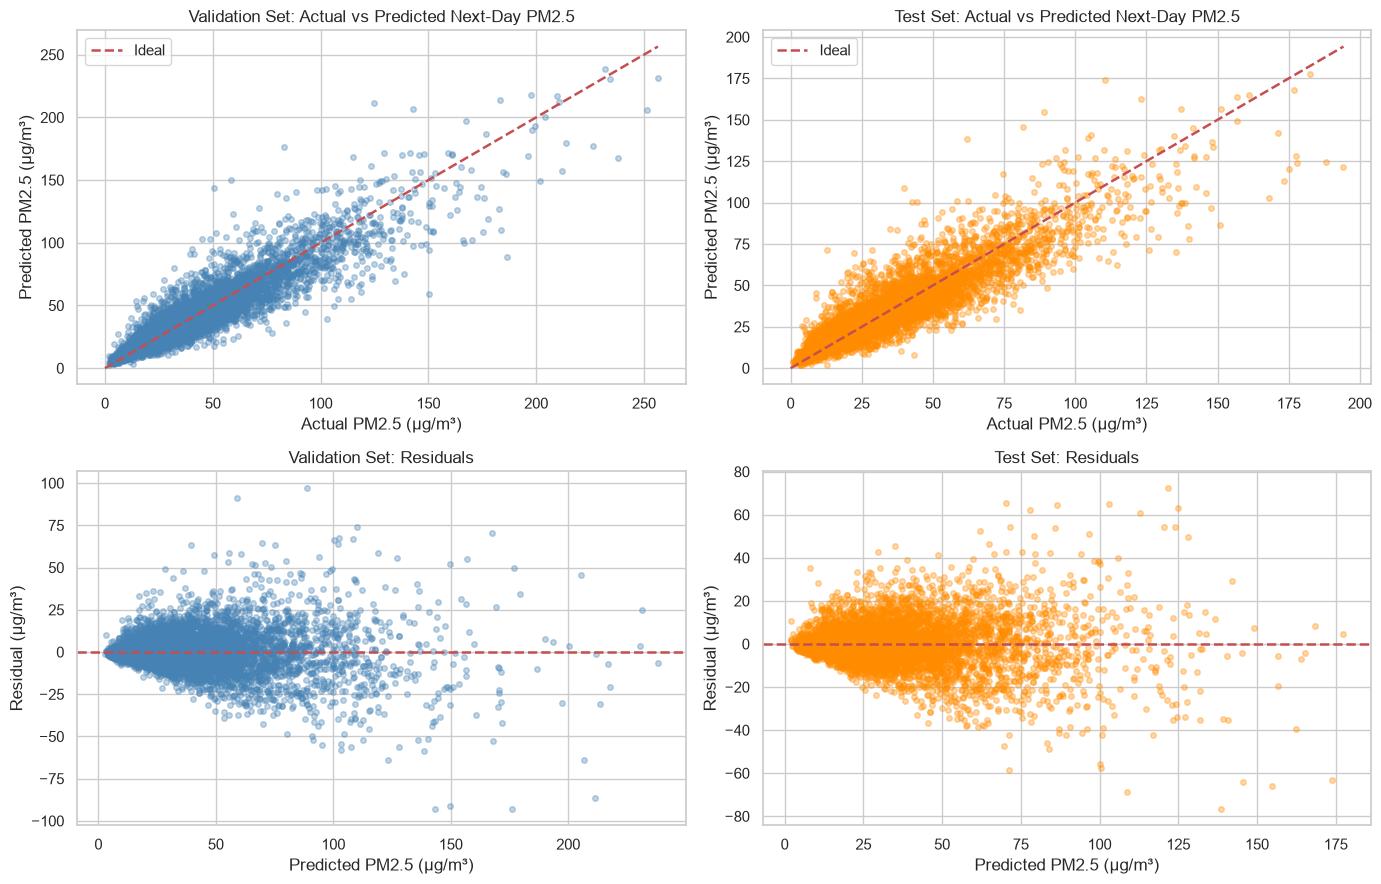

In [6]:
# Diagnostic plots: Actual vs Predicted and Residuals
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col_idx, (label, frame, preds, color) in enumerate([
    ('Validation Set', valid_df, pred_val, 'steelblue'),
    ('Test Set', test_df, pred_test, 'darkorange'),
]):
    y_true = frame['target_pm25']
    residuals = y_true - preds

    axes[0, col_idx].scatter(y_true, preds, alpha=0.35, s=16, color=color)
    lims = [0, max(y_true.max(), preds.max())]
    axes[0, col_idx].plot(lims, lims, color='r', linestyle='dashed', lw=1.8, label='Ideal')
    axes[0, col_idx].set_title(f'{label}: Actual vs Predicted Next-Day PM2.5')
    axes[0, col_idx].set_xlabel('Actual PM2.5 (µg/m³)')
    axes[0, col_idx].set_ylabel('Predicted PM2.5 (µg/m³)')
    axes[0, col_idx].legend()

    axes[1, col_idx].scatter(preds, residuals, alpha=0.35, s=16, color=color)
    axes[1, col_idx].axhline(0, color='r', linestyle='dashed', lw=1.8)
    axes[1, col_idx].set_title(f'{label}: Residuals')
    axes[1, col_idx].set_xlabel('Predicted PM2.5 (µg/m³)')
    axes[1, col_idx].set_ylabel('Residual (µg/m³)')

plt.tight_layout()
fig.savefig('visualizations/model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Interactive Air Quality Dashboard

Select any of the 50 cities to inspect:
- Next-day (`t+1`) `pm2_5_mean` forecast (`µg/m³`) and India PM2.5 AQI category
- Last 30-day actual vs. predicted time series and top 5 pollutant correlations
- Interactive 50-city Folium map exported to `visualizations/air_quality_map.html`

Output()

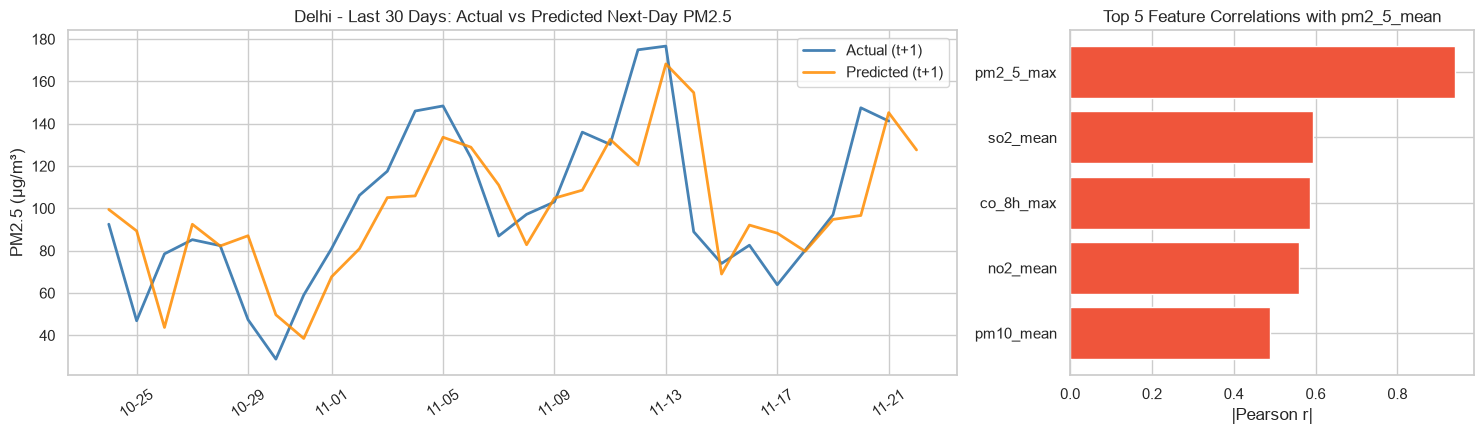

In [7]:
CITY_COORDINATES = {
    'Agartala': (23.8315, 91.2868), 'Agra': (27.1767, 78.0081), 'Ahmedabad': (23.0225, 72.5714),
    'Amritsar': (31.6340, 74.8723), 'Bengaluru': (12.9716, 77.5946), 'Bhopal': (23.2599, 77.4126),
    'Bhubaneswar': (20.2961, 85.8245), 'Chandigarh': (30.7333, 76.7794), 'Chennai': (13.0827, 80.2707),
    'Coimbatore': (11.0168, 76.9558), 'Dehradun': (30.3165, 78.0322), 'Delhi': (28.6139, 77.2090),
    'Gangtok': (27.3389, 88.6065), 'Guwahati': (26.1445, 91.7362), 'Gwalior': (26.2183, 78.1828),
    'Hyderabad': (17.3850, 78.4867), 'Imphal': (24.8170, 93.9368), 'Indore': (22.7196, 75.8577),
    'Jaipur': (26.9124, 75.7873), 'Jammu': (32.7266, 74.8570), 'Jodhpur': (26.2389, 73.0243),
    'Kanpur': (26.4499, 80.3319), 'Kochi': (9.9312, 76.2673), 'Kolkata': (22.5726, 88.3639),
    'Leh': (34.1526, 77.5771), 'Lucknow': (26.8467, 80.9462), 'Ludhiana': (30.9010, 75.8573),
    'Madurai': (9.9252, 78.1198), 'Mangaluru': (12.9141, 74.8560), 'Mumbai': (19.0760, 72.8777),
    'Mysuru': (12.2958, 76.6394), 'Nagpur': (21.1458, 79.0882), 'Nashik': (19.9975, 73.7898),
    'Panaji': (15.4909, 73.8278), 'Patna': (25.5941, 85.1376), 'Port Blair': (11.6234, 92.7265),
    'Prayagraj': (25.4358, 81.8463), 'Puducherry': (11.9416, 79.8083), 'Pune': (18.5204, 73.8567),
    'Raipur': (21.2514, 81.6296), 'Ranchi': (23.3441, 85.3096), 'Shillong': (25.5788, 91.8933),
    'Shimla': (31.1048, 77.1734), 'Srinagar': (34.0837, 74.7973), 'Surat': (21.1702, 72.8311),
    'Thiruvananthapuram': (8.5241, 76.9366), 'Vadodara': (22.3072, 73.1812), 'Varanasi': (25.3176, 82.9739),
    'Vijayawada': (16.5062, 80.6480), 'Visakhapatnam': (17.6868, 83.2185),
}

loaded_artifact = joblib.load('model/air_quality_linear_regression_model.pkl')
dash_model = loaded_artifact['model']
dash_features = loaded_artifact['feature_columns']


def pm25_category(val: float):
    if val <= 30:
        return 'Good', '#2ecc71'
    if val <= 60:
        return 'Satisfactory', '#27ae60'
    if val <= 90:
        return 'Moderate', '#f39c12'
    if val <= 120:
        return 'Poor', '#e67e22'
    if val <= 250:
        return 'Very Poor', '#e74c3c'
    return 'Severe', '#8e44ad'


all_eng = create_engineered_features(df, include_target=False)
all_eng['pred_next_pm25'] = np.maximum(dash_model.predict(all_eng[dash_features]), 0)

class CitySummary(TypedDict):
    df: pd.DataFrame
    next_date: pd.Timestamp
    next_pred: float
    last_actual: float


city_latest_summary: dict[str, CitySummary] = {}
for city_name, city_group in all_eng.groupby('city'):
    city_group = city_group.sort_values('date')
    latest_date = pd.Timestamp(city_group['date'].iloc[-1])
    city_latest_summary[str(city_name)] = {
        'df': city_group,
        'next_date': latest_date + pd.Timedelta(days=1),
        'next_pred': float(city_group['pred_next_pm25'].iloc[-1]),
        'last_actual': float(city_group['pm2_5_mean'].iloc[-1]),
    }

city_dropdown = widgets.Dropdown(
    options=sorted(CITY_COORDINATES.keys()),
    value='Delhi',
    description='City:',
    style={'description_width': '50px'},
)
refresh_btn = widgets.Button(description='Render Dashboard', button_style='primary', icon='chart-line')
dash_output = widgets.Output()


def render_dashboard(_=None):
    with dash_output:
        clear_output()
        city = city_dropdown.value
        info = city_latest_summary[city]
        cat_label, cat_color = pm25_category(info['next_pred'])

        display(HTML(f"""
        <div style="background:#1f2937;color:#f9fafb;padding:14px 18px;border-radius:8px;border-left:6px solid {cat_color};margin-bottom:10px;">
            <h3 style="margin:0 0 6px 0;">{city} - Next-Day PM2.5 Forecast</h3>
            <div>
                <b>Forecast ({info['next_date']:%Y-%m-%d}):</b> {info['next_pred']:.2f} µg/m³
                (Last observed: {info['last_actual']:.2f} µg/m³) - <b>{cat_label}</b>
            </div>
        </div>
        """))

        city_df = info['df']
        n_pts = min(30, len(city_df) - 1)
        ts_dates = city_df['date'].iloc[-n_pts:] + pd.Timedelta(days=1)
        ts_actual = city_df['pm2_5_mean'].shift(-1).iloc[-n_pts:]
        ts_pred = city_df['pred_next_pm25'].iloc[-n_pts:]

        fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2.2, 1]})
        axes[0].plot(ts_dates, ts_actual, label='Actual (t+1)', linewidth=2, color='steelblue')
        axes[0].plot(ts_dates, ts_pred, label='Predicted (t+1)', linewidth=2, color='darkorange', alpha=0.85)
        axes[0].set_title(f'{city} - Last 30 Days: Actual vs Predicted Next-Day PM2.5')
        axes[0].set_ylabel('PM2.5 (µg/m³)')
        axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
        axes[0].tick_params(axis='x', rotation=35)
        axes[0].legend()

        corr_cols = [c for c in pollutant_cols if c != 'pm2_5_mean']
        city_raw = df[df['city'] == city]
        city_corr = city_raw[corr_cols + ['pm2_5_mean']].corr()['pm2_5_mean'].drop('pm2_5_mean')
        top5 = city_corr.reindex(city_corr.abs().sort_values(ascending=False).head(5).index)
        bar_colors = ['#ef553b' if v > 0 else '#636efa' for v in top5.values]
        axes[1].barh(top5.index, top5.abs().values, color=bar_colors)
        axes[1].invert_yaxis()
        axes[1].set_title('Top 5 Feature Correlations with pm2_5_mean')
        axes[1].set_xlabel('|Pearson r|')

        plt.tight_layout()
        fig.savefig('visualizations/city_dashboard_overview.png', dpi=150, bbox_inches='tight')
        plt.show()

        aq_map = folium.Map(location=[22.5, 79.0], zoom_start=5, tiles='Esri.WorldTopoMap')
        for name, (lat, lon) in CITY_COORDINATES.items():
            if name not in city_latest_summary:
                continue
            c_info = city_latest_summary[name]
            c_cat, c_color = pm25_category(c_info['next_pred'])
            popup_html = (
                f"<b>{name}</b><br>"
                f"Next-Day Pred ({c_info['next_date']:%Y-%m-%d}): {c_info['next_pred']:.2f} µg/m³ ({c_cat})<br>"
                f"Last Actual: {c_info['last_actual']:.2f} µg/m³"
            )
            folium.CircleMarker(
                location=[lat, lon],
                radius=10 if name == city else 6,
                color=c_color,
                fill=True,
                fill_color=c_color,
                fill_opacity=0.85,
                popup=folium.Popup(popup_html, max_width=280),
            ).add_to(aq_map)

        map_path = 'visualizations/air_quality_map.html'
        aq_map.save(map_path)
        display(IFrame(src=map_path, width='100%', height='440px'))


refresh_btn.on_click(render_dashboard)
display(widgets.HBox([city_dropdown, refresh_btn]), dash_output)
render_dashboard()